In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

print("Libraries ready!")

Libraries ready!


In [4]:
url = "https://huggingface.co/datasets/hugginglearners/netflix-shows/resolve/main/netflix_titles.csv"

response = requests.get(url)
response.raise_for_status()

with open("netflix_titles.csv", "wb") as f:
    f.write(response.content)

print("Netflix dataset downloaded successfully!")

Netflix dataset downloaded successfully!


In [7]:
df = pd.read_csv("netflix_titles.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (8807, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
list

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Create a working copy
df_clean = df.copy()

# Convert date_added to datetime
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"].str.strip(),
    errors="coerce"
)

# Fill missing categorical values
for col in ["director", "cast", "country", "rating"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Extract year and month added
df_clean["year_added"] = df_clean["date_added"].dt.year
df_clean["month_added"] = df_clean["date_added"].dt.month_name()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum())

Original shape: (8807, 12)
Cleaned shape: (8807, 14)

Remaining missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
year_added      10
month_added     10
dtype: int64


In [11]:
print("Content Type Distribution:")
print(df_clean["type"].value_counts())

print("\nTop 10 Content-Producing Countries:")
print(df_clean["country"].value_counts().head(10))

print("\nContent Release Year Summary:")
print(df_clean["release_year"].describe())

print("\nMovie and TV Show Distribution:")
display(df_clean.groupby("type")["show_id"].count())

Content Type Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Top 10 Content-Producing Countries:
country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64

Content Release Year Summary:
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

Movie and TV Show Distribution:


type
Movie      6131
TV Show    2676
Name: show_id, dtype: int64

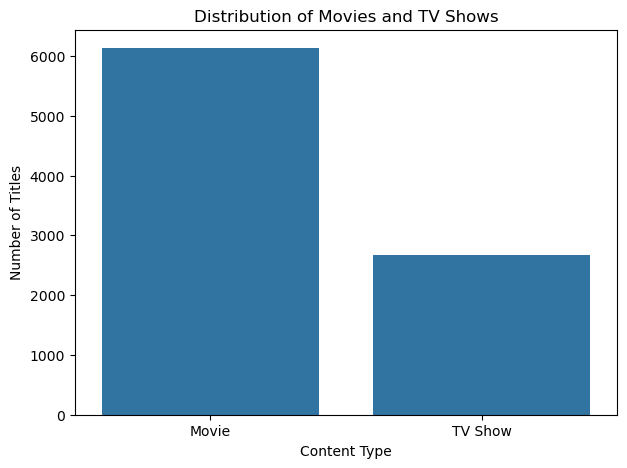

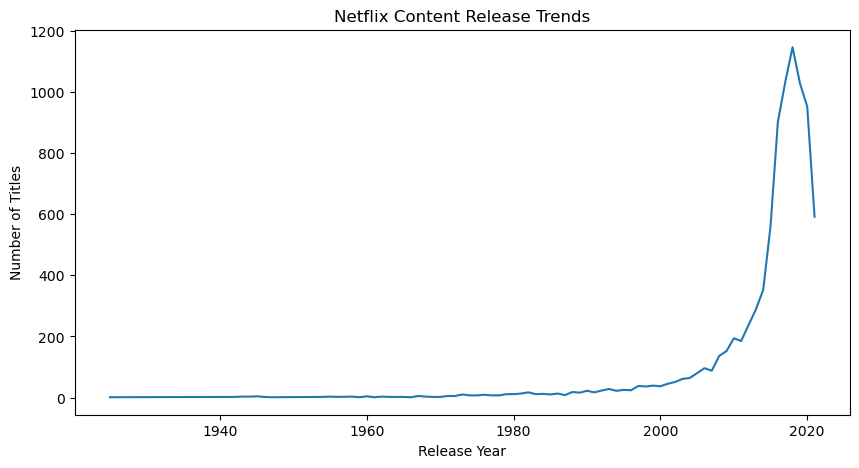

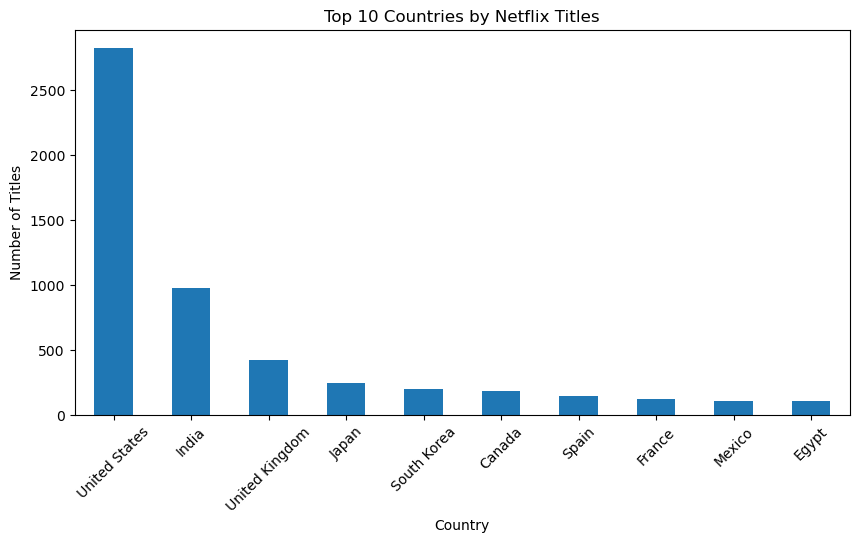

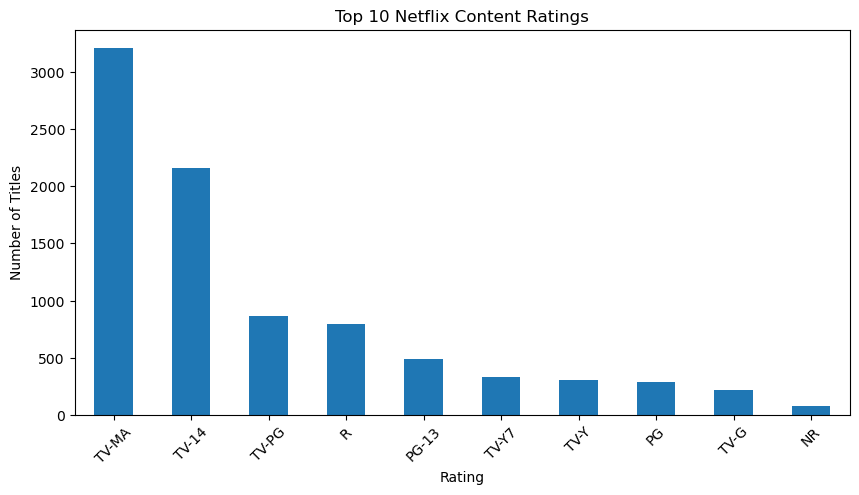

In [12]:
# 1. Movies vs TV Shows
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="type")
plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.savefig("content_type_distribution.png", bbox_inches="tight")
plt.show()

# 2. Content released by year
plt.figure(figsize=(10, 5))
df_clean["release_year"].value_counts().sort_index().plot()
plt.title("Netflix Content Release Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.savefig("release_year_trend.png", bbox_inches="tight")
plt.show()

# 3. Top 10 countries
plt.figure(figsize=(10, 5))
df_clean[df_clean["country"] != "Unknown"]["country"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.savefig("top_countries.png", bbox_inches="tight")
plt.show()

# 4. Content ratings
plt.figure(figsize=(10, 5))
df_clean["rating"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.savefig("content_ratings.png", bbox_inches="tight")
plt.show()

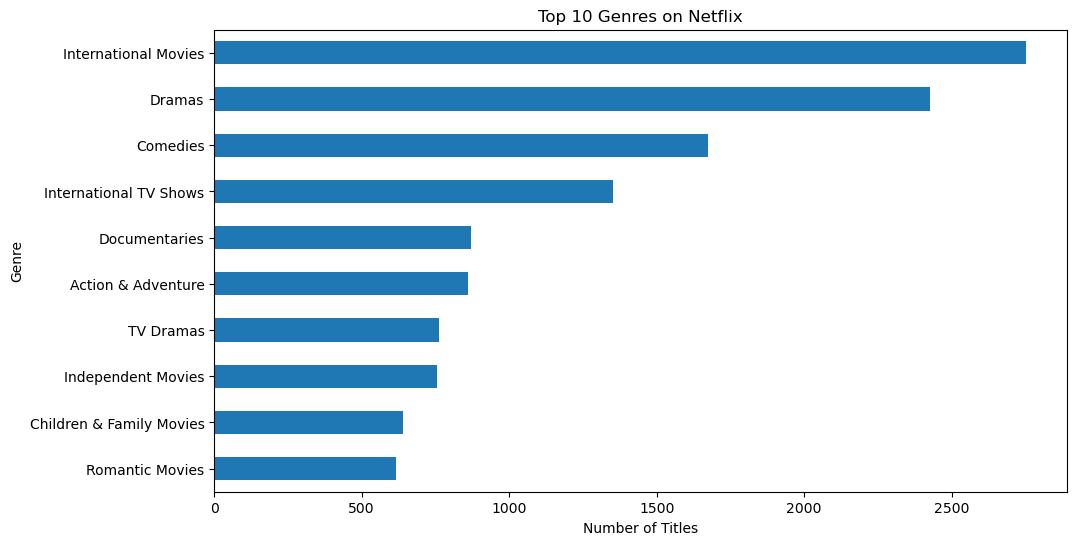

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [13]:
# Split multiple genres and count them
genres = df_clean["listed_in"].dropna().str.split(", ").explode()

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(11, 6))
top_genres.sort_values().plot(kind="barh")
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.savefig("top_genres.png", bbox_inches="tight")
plt.show()

print(top_genres)

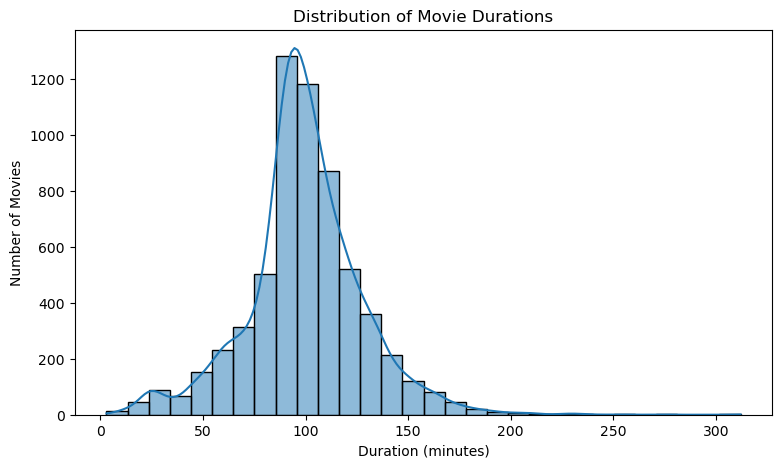

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


In [14]:
movies = df_clean[df_clean["type"] == "Movie"].copy()

movies["duration_minutes"] = (
    movies["duration"].str.extract(r"(\d+)")[0].astype(float)
)

plt.figure(figsize=(9, 5))
sns.histplot(movies["duration_minutes"].dropna(), bins=30, kde=True)
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.savefig("movie_duration.png", bbox_inches="tight")
plt.show()

print(movies["duration_minutes"].describe())

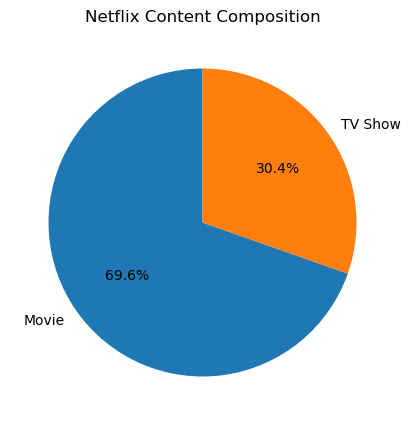

In [15]:
type_counts = df_clean.groupby("type")["show_id"].count()

plt.figure(figsize=(7, 5))
type_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Netflix Content Composition")
plt.ylabel("")
plt.savefig("content_composition.png", bbox_inches="tight")
plt.show()


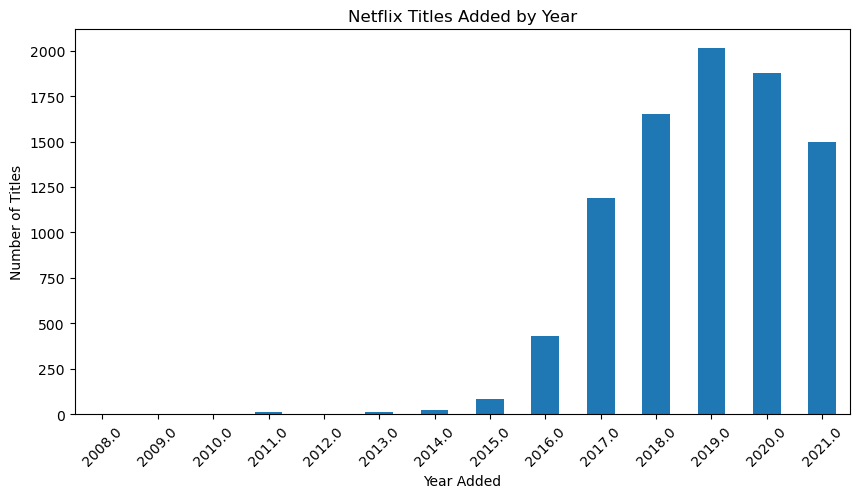

In [16]:
added_year = df_clean["year_added"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
added_year.plot(kind="bar")
plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.savefig("titles_added_by_year.png", bbox_inches="tight")
plt.show()

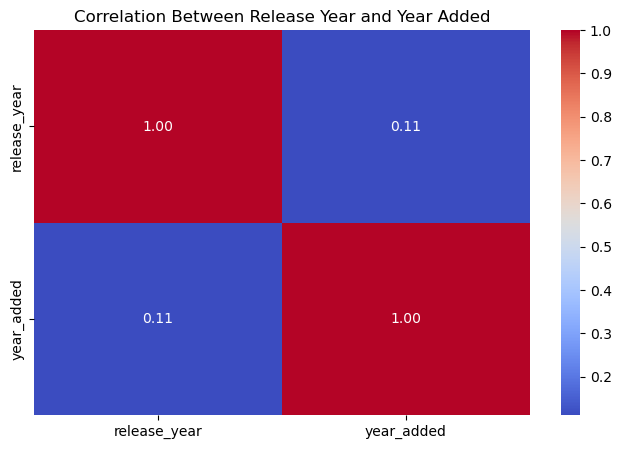

In [17]:
plt.figure(figsize=(8, 5))
correlation = df_clean[["release_year", "year_added"]].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Release Year and Year Added")
plt.savefig("correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [18]:
df_clean.to_csv("Netflix_Cleaned_Data.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df_clean.shape)

Cleaned dataset saved successfully!
Final dataset shape: (8807, 14)


In [20]:
# Key EDA findings
total_titles = len(df_clean)
movie_count = (df_clean["type"] == "Movie").sum()
tv_count = (df_clean["type"] == "TV Show").sum()

movie_percentage = movie_count / total_titles * 100
tv_percentage = tv_count / total_titles * 100

print("========== NETFLIX EDA SUMMARY ==========")
print("Total titles:", total_titles)
print("Movies:", movie_count)
print("TV Shows:", tv_count)
print(f"Movies percentage: {movie_percentage:.2f}%")
print(f"TV Shows percentage: {tv_percentage:.2f}%")

print("\nMost common genre:")
print(genres.value_counts().head(1))

print("\nMost common content rating:")
print(df_clean["rating"].value_counts().head(1))

print("\nAverage movie duration:")
print(round(movies["duration_minutes"].mean(), 2), "minutes")

print("\nEarliest release year:", df_clean["release_year"].min())
print("Latest release year:", df_clean["release_year"].max())

========== NETFLIX EDA SUMMARY ==========
Total titles: 8807
Movies: 6131
TV Shows: 2676
Movies percentage: 69.62%
TV Shows percentage: 30.38%

Most common genre:
listed_in
International Movies    2752
Name: count, dtype: int64

Most common content rating:
rating
TV-MA    3207
Name: count, dtype: int64

Average movie duration:
99.58 minutes

Earliest release year: 1925
Latest release year: 2021


In [21]:
# Export useful summary tables
type_summary = df_clean["type"].value_counts().reset_index()
type_summary.columns = ["Content Type", "Number of Titles"]

genre_summary = genres.value_counts().head(10).reset_index()
genre_summary.columns = ["Genre", "Number of Titles"]

country_summary = (
    df_clean[df_clean["country"] != "Unknown"]["country"]
    .value_counts().head(10).reset_index()
)
country_summary.columns = ["Country", "Number of Titles"]

type_summary.to_csv("Netflix_Type_Summary.csv", index=False)
genre_summary.to_csv("Netflix_Genre_Summary.csv", index=False)
country_summary.to_csv("Netflix_Country_Summary.csv", index=False)

print("Analysis summary files saved successfully!")

Analysis summary files saved successfully!


In [22]:
print("WEEK 2 EDA CHECKLIST")
print("1. Dataset loaded:", not df.empty)
print("2. Data cleaning completed:", not df_clean.empty)
print("3. Genre analysis completed:", len(genres) > 0)
print("4. Movie analysis completed:", not movies.empty)
print("5. Cleaned CSV exists in notebook folder.")
print("6. Analysis charts generated.")

WEEK 2 EDA CHECKLIST
1. Dataset loaded: True
2. Data cleaning completed: True
3. Genre analysis completed: True
4. Movie analysis completed: True
5. Cleaned CSV exists in notebook folder.
6. Analysis charts generated.


In [23]:
import os

print("GENERATED FILES:")
for file in os.listdir():
    if file.endswith((".png", ".csv", ".ipynb")):
        print(file)

GENERATED FILES:
content_composition.png
content_ratings.png
content_type_distribution.png
correlation_heatmap.png
GDP_Trend.png
Inflation_Trend.png
movie_duration.png
Netflix_Cleaned_Data.csv
Netflix_Country_Summary.csv
Netflix_Genre_Summary.csv
netflix_titles.csv
Netflix_Type_Summary.csv
Population_Trend.png
release_year_trend.png
titles_added_by_year.png
top_countries.png
top_genres.png
Unemployment_Trend.png
YUVA_Data_Cleaning_Summary.csv
YUVA_India_Cleaned_Data.csv
YUVA_India_Original_Data.csv
YUVA_Week1_Data_Cleaning.ipynb
YUVA_Week2_Netflix_EDA.ipynb
